In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py
plt.rcParams['figure.figsize'] = (12,6)

In [2]:
hf = h5py.File('gammaray_lab4.h5', 'r')
hf.keys()
data = np.array(hf.get('data'))
hf.close()

In [3]:
np.shape(data)

(4, 25920001)

In [4]:
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

# Problem 1

In [5]:
#set time of the first data to 0 to simplify the plot
t0=data[0,0]
data[0]=data[0]-t0

Text(0, 0.5, 'Particles in 100ms (N)')

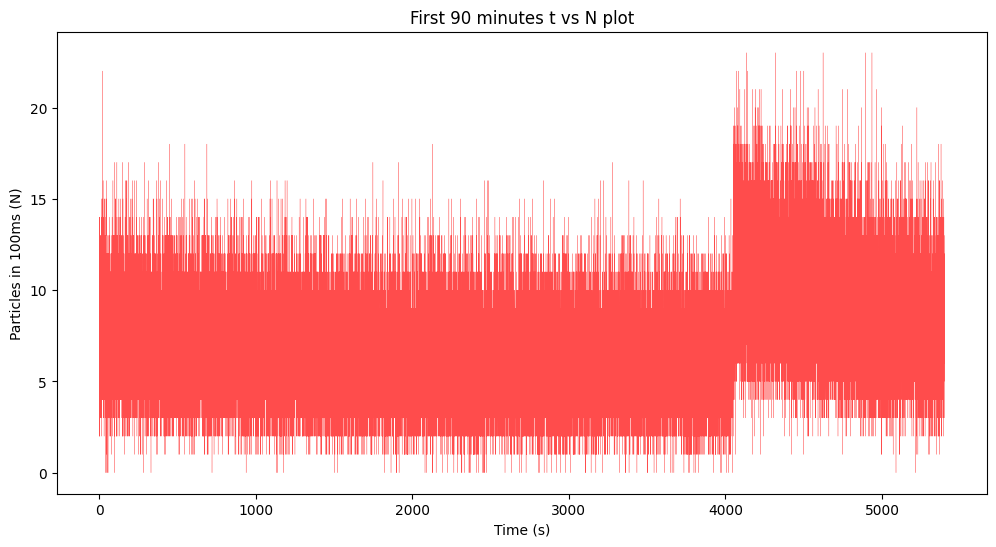

In [6]:
#plot the first 90 minutes
plt.plot(data[0,:54000],data[3,:54000],linewidth=0.2,c="r",alpha=0.7)
plt.title("First 90 minutes t vs N plot")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")

Text(0, 0.5, 'Particles in 100ms (N)')

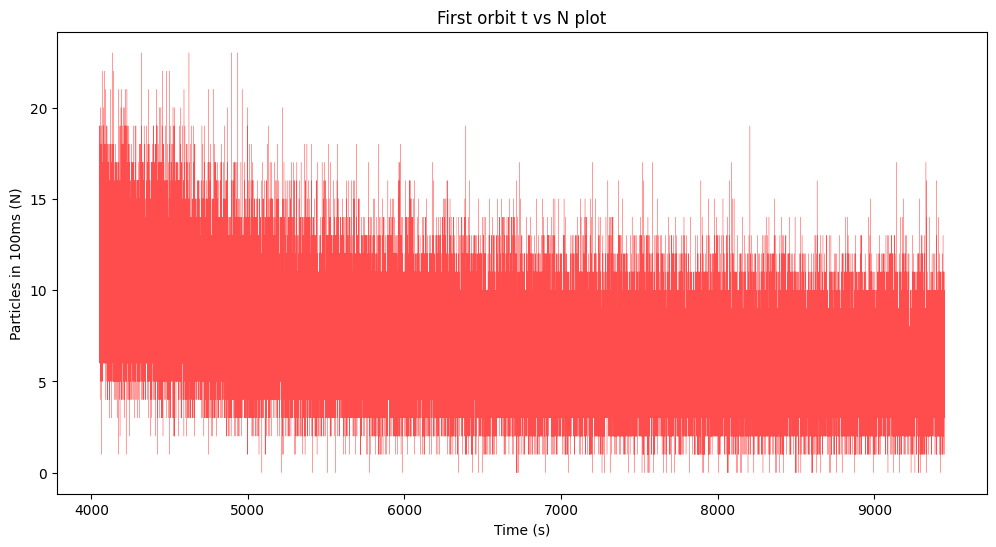

In [7]:
#let's change the range of t to [40500,94500]
plt.plot(data[0,40500:94500],data[3,40500:94500],linewidth=0.2,c="r",alpha=0.7)
plt.title("First orbit t vs N plot")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")

Text(0, 0.5, 'Particles in 100ms (N)')

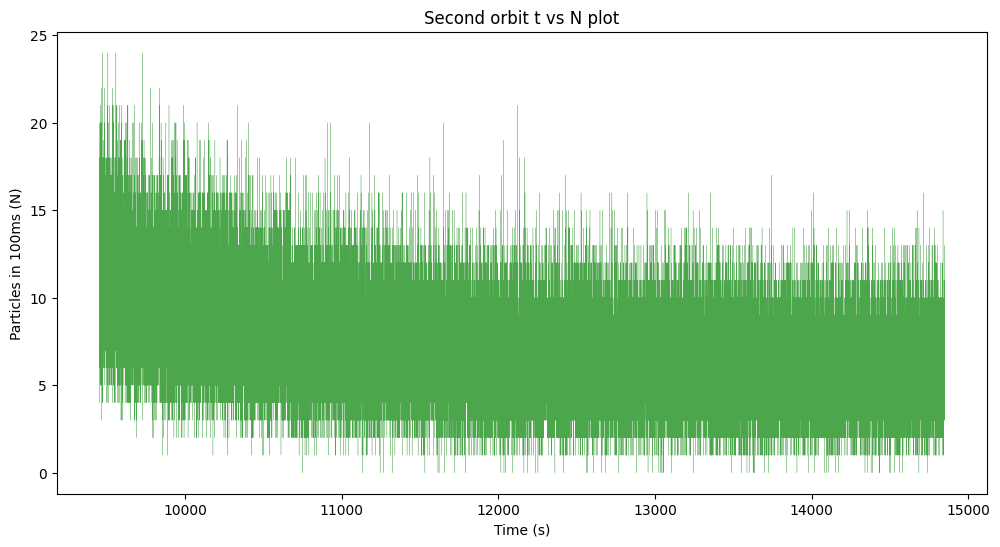

In [8]:
#plot the second orbit to compare with the first one
plt.plot(data[0,94500:148500],data[3,94500:148500],linewidth=0.2,c="g",alpha=0.7)
plt.title("Second orbit t vs N plot")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")

Text(0, 0.5, 'Particles in 100ms (N)')

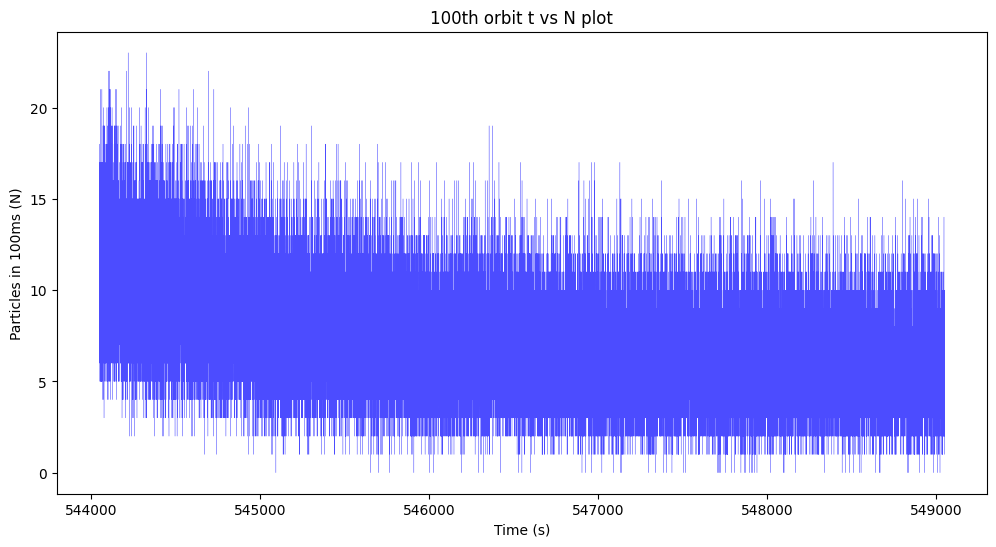

In [9]:
#let's see 100th orbit
plt.plot(data[0,5440500:5490500],data[3,5440500:5490500],linewidth=0.2,c="b",alpha=0.7)
plt.title("100th orbit t vs N plot")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")

It has the same shape

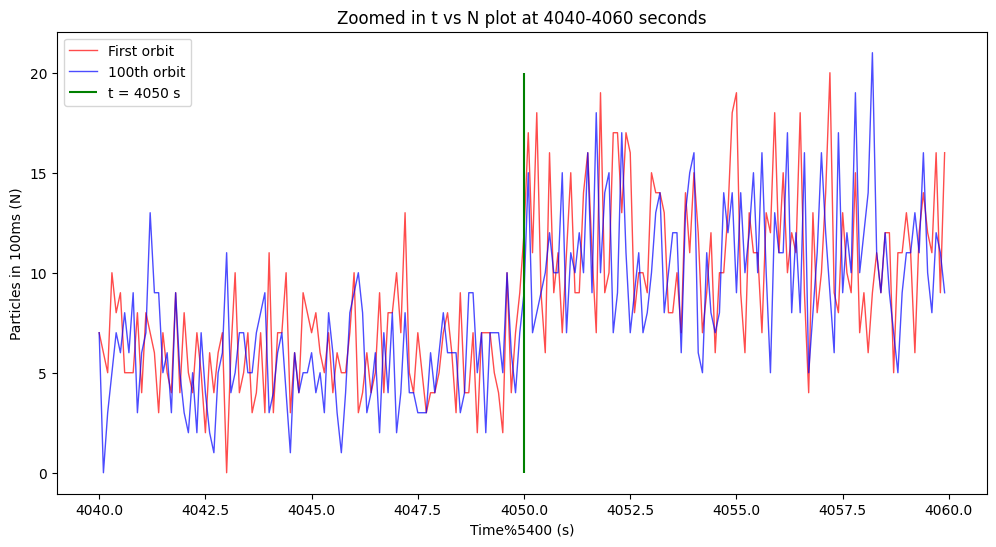

In [10]:
#zoom into the sudden change around 4040 to 4060 seconds
plt.plot(data[0,40400:40600],data[3,40400:40600],linewidth=1,c="r",alpha=0.7,label="First orbit")
plt.plot(data[0,5440400:5440600]-540000,data[3,5440400:5440600],linewidth=1,c="b",alpha=0.7,label="100th orbit")
plt.vlines(4050,0,20,colors="g",label="t = 4050 s")
plt.title("Zoomed in t vs N plot at 4040-4060 seconds")
plt.xlabel("Time%5400 (s)")
plt.ylabel("Particles in 100ms (N)")
plt.legend()

Now, we know that the sudden change occurs around t = 4050 seconds.
Let's see the Time vs Solar phase and Earth's longitude.

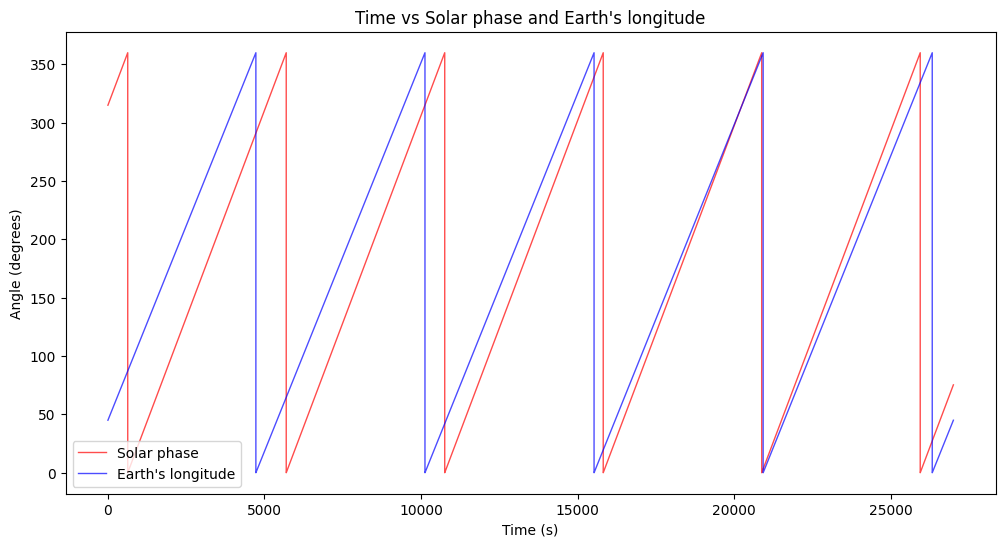

In [11]:
plt.plot(data[0,:270000],data[1,:270000],linewidth=1,c="r",alpha=0.7,label="Solar phase")
plt.plot(data[0,:270000],data[2,:270000],linewidth=1,c="b",alpha=0.7,label="Earth's longitude")
plt.title("Time vs Solar phase and Earth's longitude")
plt.xlabel("Time (s)")
plt.ylabel("Angle (degrees)")
plt.legend()

As we can see, the Sun phase and Earth longitude increases over time until they go to 360 and got reset to 0. The Sun phase (Red) seems to have shorter period than Earth longitude (Blue).

In [12]:
(27000+np.argmax(data[1,27000:81000])-np.argmax(data[1,0:27000]))/10

np.float64(5061.6)

In [13]:
(54000+np.argmax(data[2,54000:108000])-np.argmax(data[2,0:54000]))/10

np.float64(5400.0)

Since we see that the period of the Sun phase is 5061.6 seconds, while the period of the Earth longitude is 5400 seconds, we can conclude that the source of sudden change in Gamma rays that happens every 5400 seconds is related to Earth longitude.

In [14]:
data[2,40500]

np.float64(315.0)

The sudden change happens when the Earth longitude is 315 degrees.

# Problem 2

In [15]:
np.max(data[3])

np.float64(30.0)

In [16]:
bins=np.arange(0,31)

Text(0, 0.5, 'Measurements')

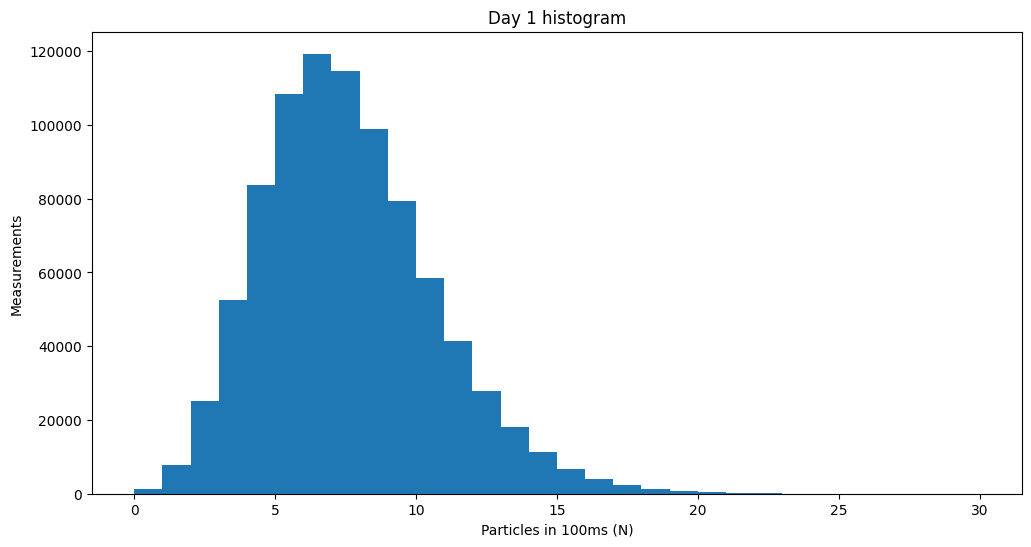

In [17]:
plt.hist(data[3,:864000],bins=bins);
plt.title("Day 1 histogram")
plt.xlabel("Particles in 100ms (N)")
plt.ylabel("Measurements")

Text(0, 0.5, 'Measurements')

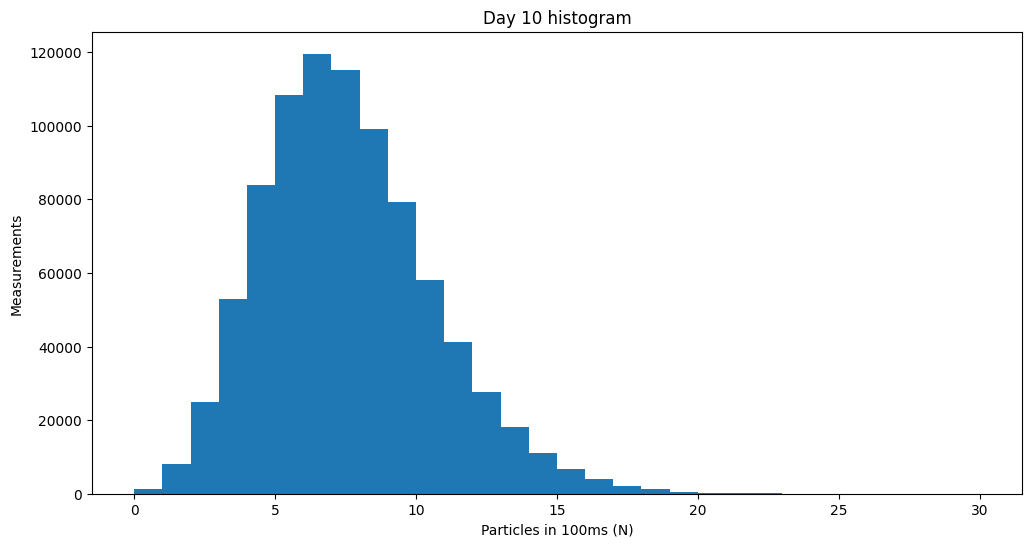

In [18]:
plt.hist(data[3,8640000:9504000],bins=30);
plt.title("Day 10 histogram")
plt.xlabel("Particles in 100ms (N)")
plt.ylabel("Measurements")

The data of day 1 vs day 10 looks the same when using histogram, so there is no visual difference in the data.

# Problem 3
First, let's clean out the noise to visualize the relationship of particles/s vs time better. We will use savgol_filter.

In [19]:
data3sm=scipy.signal.savgol_filter(data[3],75,3)

Text(0, 0.5, 'Particles in 100ms (N)')

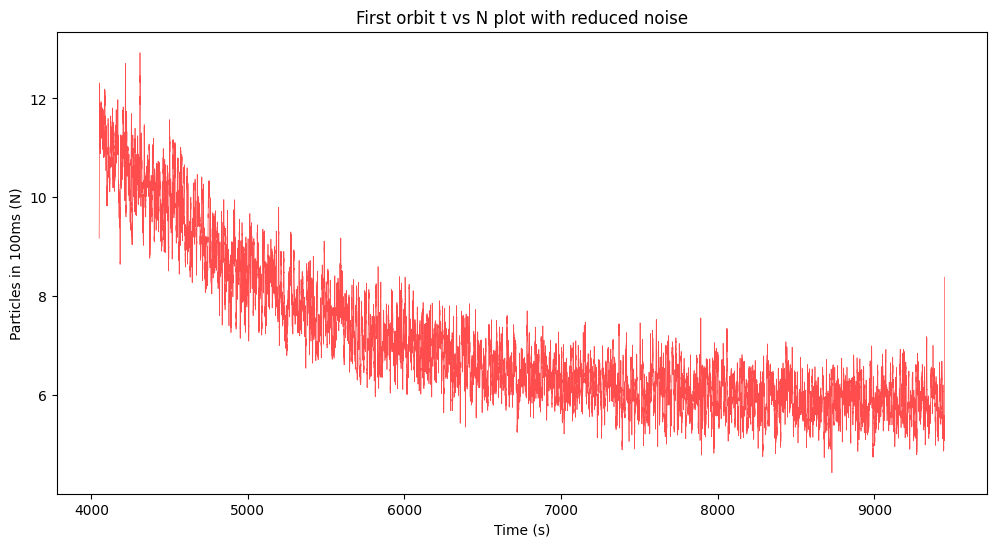

In [20]:
#for visualization purpose only, not for calculation.
plt.plot(data[0,40500:94500],data3sm[40500:94500],linewidth=0.5,c="r",alpha=0.7)
plt.title("First orbit t vs N plot with reduced noise")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")

In [21]:
from scipy.optimize import curve_fit

In [22]:
def func(x,a,b,c):
    x=(x/5400-0.75)%1
    return a*np.exp(-b*x)+c
popt,pcov=curve_fit(func,data[0],data[3])

In [23]:
print(f"The model that I got is N = {popt[0]:.3f}*e^(-{popt[1]:.3f}*(t/5400-0.75)%1) +{popt[2]:.3f}")

The model that I got is N = 5.694*e^(-3.995*(t/5400-0.75)%1) +5.698


In [24]:
fitdata=func(data[0],*popt)

In [25]:
errors=np.sqrt(np.diag(pcov))
errors

array([0.00212778, 0.00378985, 0.00131336])

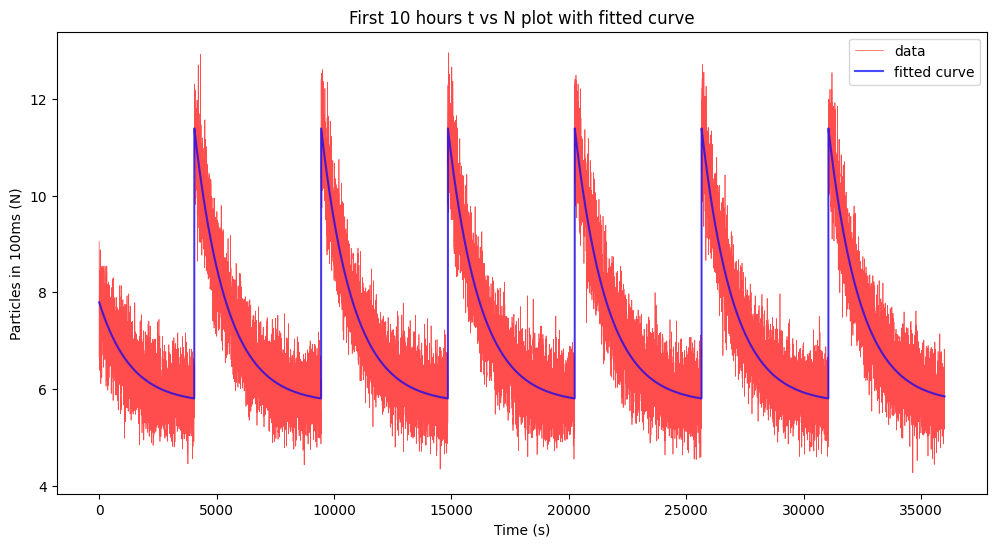

In [26]:
#for visualization only, not for calculation.
plt.plot(data[0,0:360000],data3sm[0:360000],linewidth=0.5,c="r",alpha=0.7,label="data")
plt.plot(data[0,0:360000],fitdata[0:360000],linewidth=1.5,c="b",alpha=0.7,label="fitted curve")
plt.title("First 10 hours t vs N plot with fitted curve")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")
plt.legend()

Now, let's find reduced chi2.

In [27]:
chi2,pval=stats.chisquare(data[3],np.sum(data[3])/np.sum(fitdata)*fitdata)

In [28]:
rchi2=chi2/len(data[3])
print(f"The reduced chi2 is {rchi2:.6f}")

The reduced chi2 is 1.000129


So, It fits (maybe good?).

# Problem 4
The $\sigma$ in this case would be $\sqrt{N}$ in which N is the particles/sec measured. So, $5\sigma$ discovery would have $N+5\sqrt{N}$ particles/sec

In [29]:
n5sig=fitdata+5*np.sqrt(fitdata)

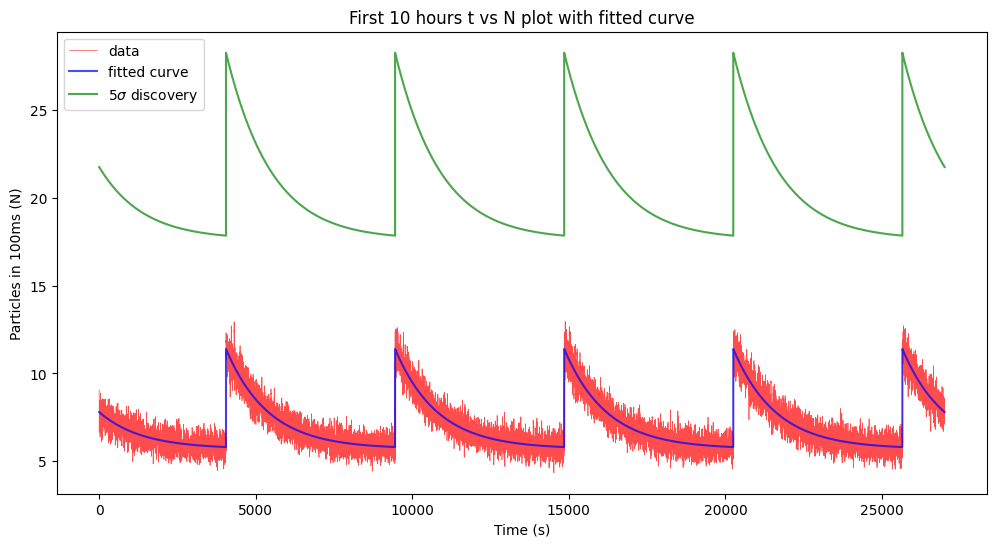

In [30]:
#for visualization only, not for calculation.
plt.plot(data[0,0:270000],data3sm[0:270000],linewidth=0.5,c="r",alpha=0.7,label="data")
plt.plot(data[0,0:270000],fitdata[0:270000],linewidth=1.5,c="b",alpha=0.7,label="fitted curve")
plt.plot(data[0,0:270000],n5sig[0:270000],linewidth=1.5,c="g",alpha=0.7,label=r"$5\sigma$ discovery")
plt.title("First 10 hours t vs N plot with fitted curve")
plt.xlabel("Time (s)")
plt.ylabel("Particles in 100ms (N)")
plt.legend()

# Problem 5
The cause of variable background has to be related to Earth's longitude = 315 degrees. There are things that could cause these bumps in particle counts. A weakspot of Earth's magnetic field at 315 degrees could allow Van Allen belt to lower down to Low Earth Orbit altitude. The another possible explanation is that there is a gamma-ray emitter from the ground at 315 degrees, this could be nuclear reactor or lightning.